In [1]:
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, make_circles, load_breast_cancer, load_digits
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, SVR
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import sklearn

plt.rcParams['figure.dpi'] = 115
print('Python:', sys.version.split()[0], 'scikit-learn:', sklearn.__version__)
print('Random seed: 42 | No data downloads required')

Python: 3.12.13 scikit-learn: 1.7.2
Random seed: 42 | No data downloads required


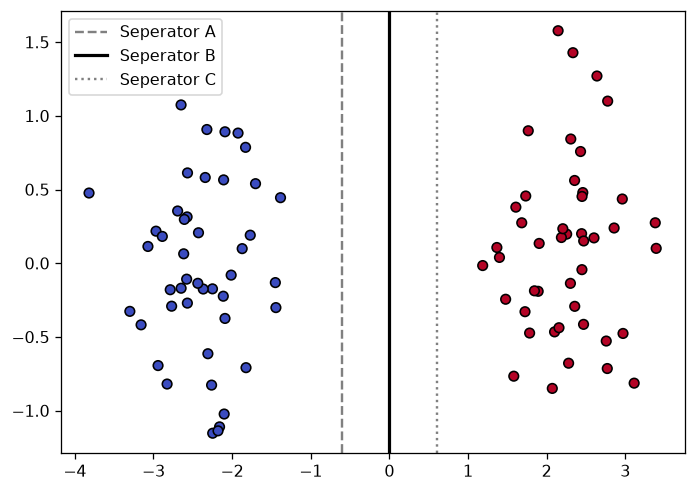

In [2]:
X_intro, y_intro = make_blobs(n_samples = 90, centers = [(-2.3, 0), (2.3, 0)],
                              cluster_std = 0.58, random_state = 42)
plt.figure(figsize = (7,5))
plt.scatter(X_intro[:,0], X_intro[:,1], c = y_intro, cmap = 'coolwarm',
            edgecolors = 'black', s=36)
plt.axvline(-0.6, color = 'gray', linestyle = '--', label = 'Seperator A')
plt.axvline(0.0, color = 'black', linewidth = 2, label = 'Seperator B')
plt.axvline(0.6, color = 'gray', linestyle = ':', label = 'Seperator C')
plt.legend()
plt.show()

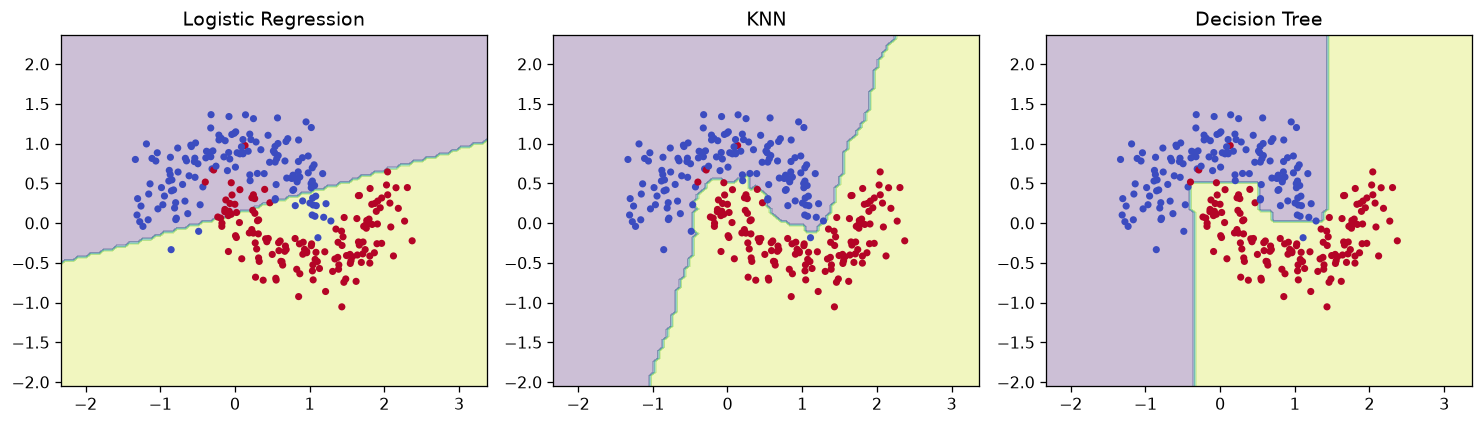

In [10]:
X_moon, y_moon = make_moons(n_samples=280, noise=0.2, random_state=42)
lr = LogisticRegression().fit(X_moon, y_moon)
knn = KNeighborsClassifier(n_neighbors=9).fit(X_moon, y_moon)
tree = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_moon, y_moon)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
DecisionBoundaryDisplay.from_estimator(lr, X_moon, ax=axes[0], alpha=0.28, response_method='predict')
axes[0].scatter(X_moon[:,0], X_moon[:,1], c=y_moon, cmap='coolwarm', s=12)
axes[0].set_title('Logistic Regression')
DecisionBoundaryDisplay.from_estimator(knn, X_moon, ax=axes[1], alpha=0.28, response_method='predict')
axes[1].scatter(X_moon[:,0], X_moon[:,1], c=y_moon, cmap='coolwarm', s=12)
axes[1].set_title('KNN')
DecisionBoundaryDisplay.from_estimator(tree, X_moon, ax=axes[2], alpha=0.28, response_method='predict')
axes[2].scatter(X_moon[:,0], X_moon[:,1], c=y_moon, cmap='coolwarm', s=12)
axes[2].set_title('Decision Tree')
plt.tight_layout(); plt.show()

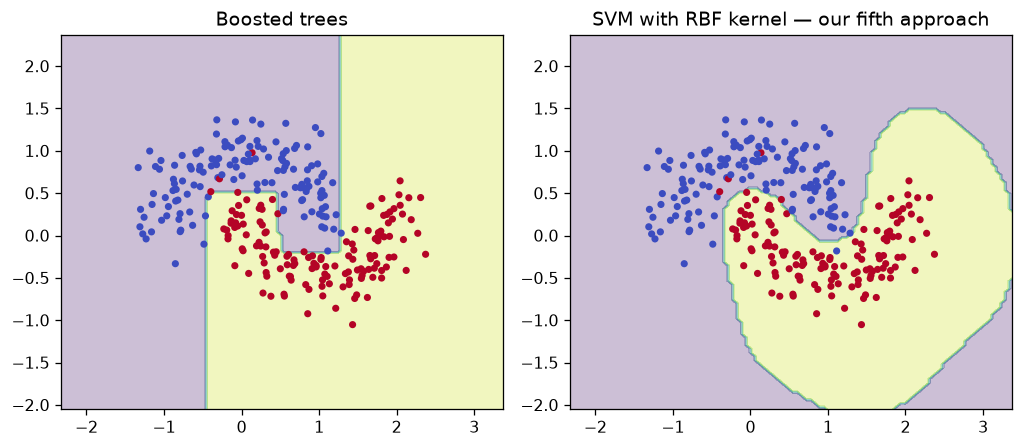

In [16]:
boost = HistGradientBoostingClassifier(max_iter=60, max_leaf_nodes=8, random_state=42).fit(X_moon, y_moon)
rbf_gallery = SVC(kernel='rbf', C=2, gamma=2).fit(X_moon, y_moon)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
DecisionBoundaryDisplay.from_estimator(boost, X_moon, ax=axes[0], alpha=0.28, response_method='predict')
axes[0].scatter(X_moon[:,0], X_moon[:,1], c=y_moon, cmap='coolwarm', s=12)
axes[0].set_title('Boosted trees')
DecisionBoundaryDisplay.from_estimator(rbf_gallery, X_moon, ax=axes[1], alpha=0.28, response_method='predict')
axes[1].scatter(X_moon[:,0], X_moon[:,1], c=y_moon, cmap='coolwarm', s=12)
axes[1].set_title('SVM with RBF kernel — our fifth approach')
plt.tight_layout(); plt.show()

w · x = 4.0
Length of w = 2.236


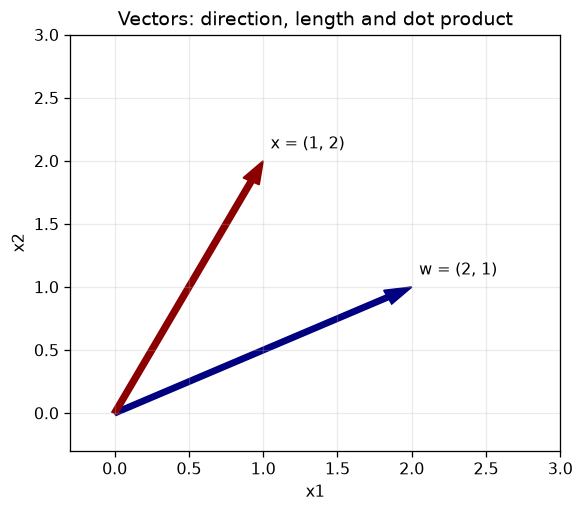

In [17]:
w_demo = np.array([2.0, 1.0])
x_demo = np.array([1.0, 2.0])
print('w · x =', np.dot(w_demo, x_demo))
print('Length of w =', round(np.linalg.norm(w_demo), 3))
plt.figure(figsize=(5.5, 4.7))
plt.arrow(0,0,w_demo[0],w_demo[1],width=0.04, color='navy', length_includes_head=True)
plt.arrow(0,0,x_demo[0],x_demo[1],width=0.04, color='darkred', length_includes_head=True)
plt.text(2.05,1.1,'w = (2, 1)'); plt.text(1.05,2.1,'x = (1, 2)')
plt.xlim(-0.3,3); plt.ylim(-0.3,3); plt.grid(alpha=0.25)
plt.xlabel('x1'); plt.ylabel('x2'); plt.title('Vectors: direction, length and dot product')
plt.show()

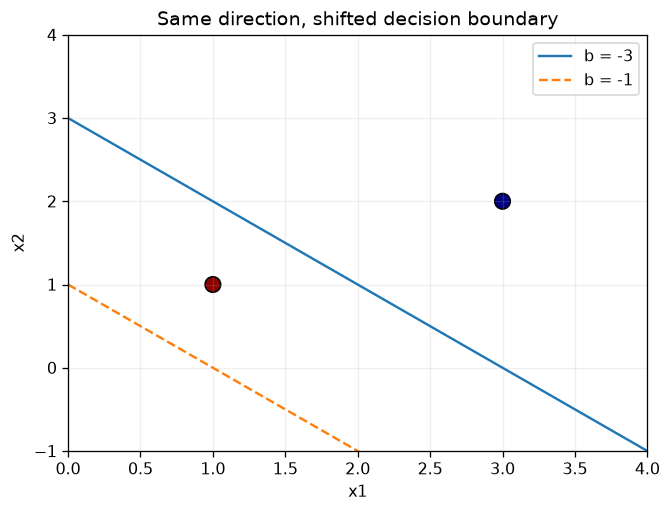

In [18]:
x_line = np.linspace(0, 4, 100)
plt.figure(figsize=(6.5, 4.7))
plt.plot(x_line, 3 - x_line, label='b = -3')
plt.plot(x_line, 1 - x_line, '--', label='b = -1')
plt.scatter([1,3],[1,2], c=['darkred','navy'], s=95, edgecolors='black')
plt.xlim(0,4); plt.ylim(-1,4); plt.grid(alpha=0.2)
plt.xlabel('x1'); plt.ylabel('x2'); plt.title('Same direction, shifted decision boundary')
plt.legend(); plt.show()

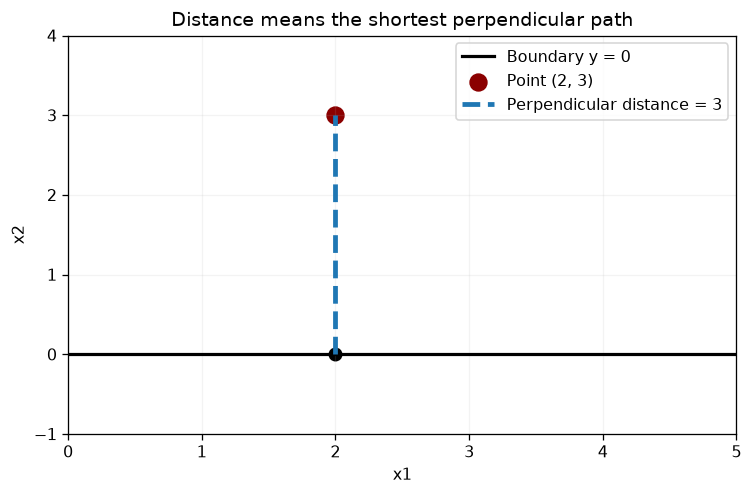

In [19]:
plt.figure(figsize=(7.5, 4.5))
plt.axhline(0, color='black', linewidth=2, label='Boundary y = 0')
plt.scatter([2],[3], s=110, c='darkred', label='Point (2, 3)')
plt.plot([2,2],[0,3], linestyle='--', linewidth=3, label='Perpendicular distance = 3')
plt.scatter([2],[0], c='black', s=60)
plt.xlim(0,5);plt.ylim(-1,4);plt.xlabel('x1');plt.ylabel('x2')
plt.title('Distance means the shortest perpendicular path')
plt.grid(alpha=0.15);plt.legend();plt.show()

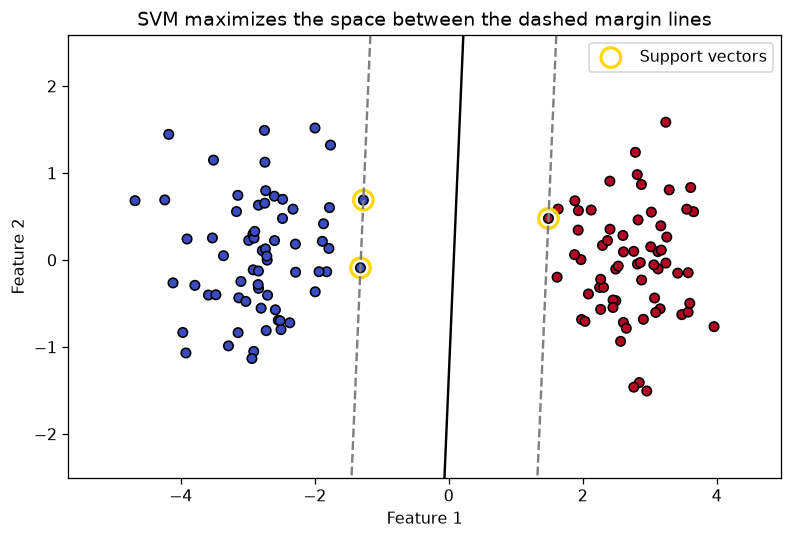

Margin width: 2.77
Number of support vectors: 3


In [20]:
X_clear, y_clear = make_blobs(n_samples=130, centers=[(-2.8,0),(2.8,0)], cluster_std=0.6, random_state=8)
svm_clear = SVC(kernel='linear', C=100).fit(X_clear, y_clear)
fig, ax = plt.subplots(figsize=(8,5))
DecisionBoundaryDisplay.from_estimator(svm_clear, X_clear, ax=ax, response_method='decision_function',
                                      plot_method='contour', levels=[-1,0,1], colors=['gray','black','gray'],
                                      linestyles=['--','-','--'])
ax.scatter(X_clear[:,0], X_clear[:,1], c=y_clear, cmap='coolwarm', s=35, edgecolors='black')
ax.scatter(svm_clear.support_vectors_[:,0], svm_clear.support_vectors_[:,1],
           s=150, facecolors='none', edgecolors='gold', linewidths=2, label='Support vectors')
ax.set_title('SVM maximizes the space between the dashed margin lines')
ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2'); ax.legend(); plt.show()
print('Margin width:', round(2/np.linalg.norm(svm_clear.coef_[0]),3))
print('Number of support vectors:',len(svm_clear.support_))

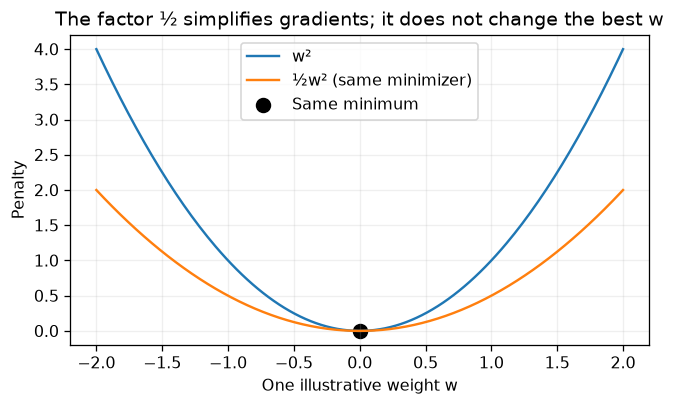

In [21]:
z = np.linspace(-2,2,200)
plt.figure(figsize=(6.5,3.5))
plt.plot(z, z**2, label='w²')
plt.plot(z, 0.5*z**2, label='½w² (same minimizer)')
plt.scatter([0],[0],s=75,c='black',label='Same minimum')
plt.title('The factor ½ simplifies gradients; it does not change the best w')
plt.xlabel('One illustrative weight w');plt.ylabel('Penalty')
plt.legend();plt.grid(alpha=.2);plt.show()

In [22]:
X_sv, y_sv = make_blobs(n_samples=500, centers=[(-2.8,0),(2.8,0)], cluster_std=1.2, random_state=7)
svm_all = SVC(kernel='linear', C=1).fit(X_sv,y_sv)
kept = svm_all.support_
svm_small = SVC(kernel='linear', C=1).fit(X_sv[kept],y_sv[kept])
log_all = LogisticRegression(C=1).fit(X_sv,y_sv)
log_small = LogisticRegression(C=1).fit(X_sv[kept],y_sv[kept])
print('Support vectors:',len(kept),'out of',len(X_sv))
print('SVM weight change:',np.round(svm_all.coef_[0]-svm_small.coef_[0],6))
print('Logistic weight change:',np.round(log_all.coef_[0]-log_small.coef_[0],6))
assert len(kept)<len(X_sv)
assert np.allclose(svm_all.coef_,svm_small.coef_,atol=0.02)

Support vectors: 12 out of 500
SVM weight change: [2.4e-05 1.0e-05]
Logistic weight change: [ 2.012982 -0.037302]


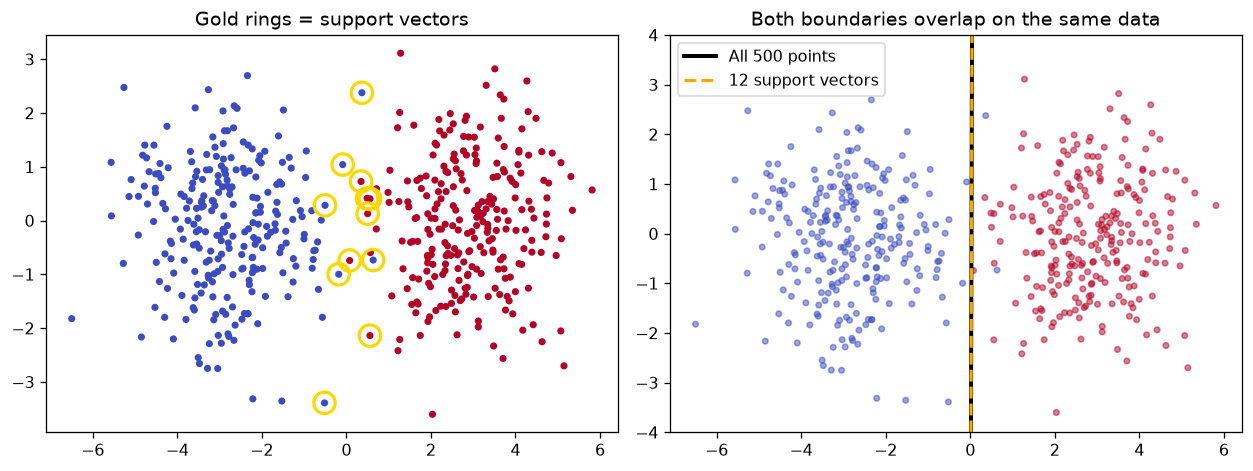

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(X_sv[:, 0], X_sv[:, 1], c=y_sv, cmap='coolwarm', s=12)
axes[0].scatter(X_sv[kept, 0], X_sv[kept, 1],
                s=180, facecolors='none', edgecolors='gold', linewidths=2)
axes[0].set_title('Gold rings = support vectors')

# Plot the same dots behind the two almost identical boundaries.
yy = np.linspace(-4, 4, 100)
x_all = -(svm_all.coef_[0, 1] * yy + svm_all.intercept_[0]) / svm_all.coef_[0, 0]
x_support = -(svm_small.coef_[0, 1] * yy + svm_small.intercept_[0]) / svm_small.coef_[0, 0]
axes[1].scatter(X_sv[:, 0], X_sv[:, 1], c=y_sv, cmap='coolwarm', s=12, alpha=0.5)
axes[1].plot(x_all, yy, color='black', linewidth=2.5, label='All 500 points')
axes[1].plot(x_support, yy, '--', color='orange', linewidth=2, label='12 support vectors')
axes[1].set_ylim(-4, 4)
axes[1].set_title('Both boundaries overlap on the same data')
axes[1].legend()
plt.tight_layout()
plt.show()

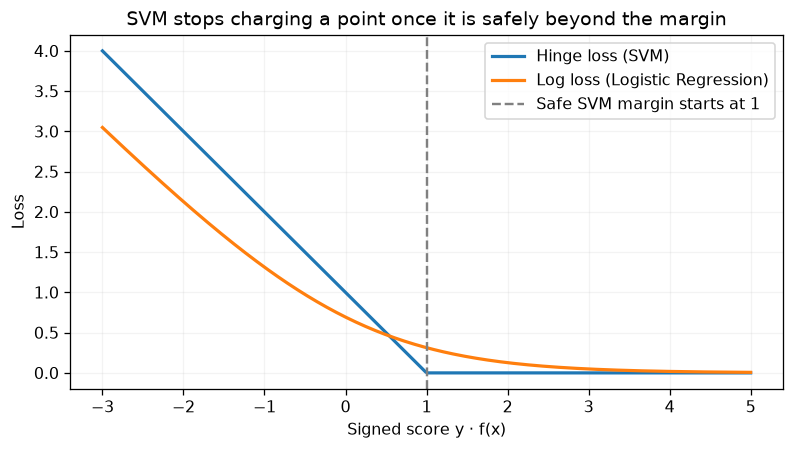

In [24]:
margin_score=np.linspace(-3,5,400)
hinge=np.maximum(0,1-margin_score)
log_loss=np.logaddexp(0,-margin_score)
plt.figure(figsize=(8,4))
plt.plot(margin_score,hinge,label='Hinge loss (SVM)',lw=2)
plt.plot(margin_score,log_loss,label='Log loss (Logistic Regression)',lw=2)
plt.axvline(1,ls='--',c='gray',label='Safe SVM margin starts at 1')
plt.xlabel('Signed score y · f(x)');plt.ylabel('Loss')
plt.title('SVM stops charging a point once it is safely beyond the margin')
plt.grid(alpha=.15);plt.legend();plt.show()

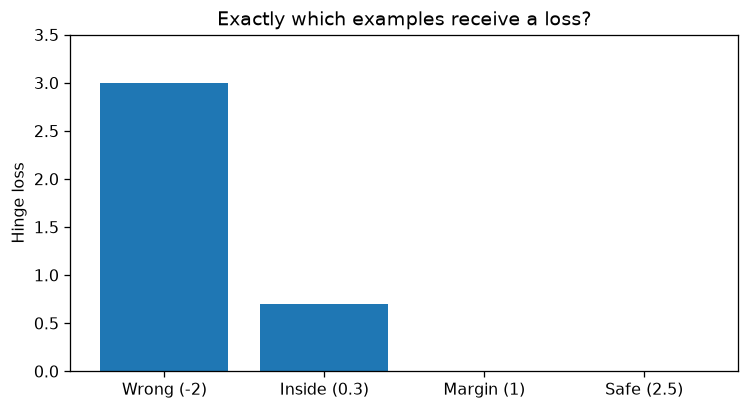

Scores: [-2.   0.3  1.   2.5]
Hinge losses: [3.  0.7 0.  0. ]


In [25]:
scores=np.array([-2.0,0.3,1.0,2.5])
losses=np.maximum(0,1-scores)
plt.figure(figsize=(7.5,3.8))
plt.bar(['Wrong (-2)','Inside (0.3)','Margin (1)','Safe (2.5)'],losses)
plt.ylabel('Hinge loss');plt.title('Exactly which examples receive a loss?')
plt.ylim(0,3.5);plt.show()
print('Scores:',scores)
print('Hinge losses:',losses)

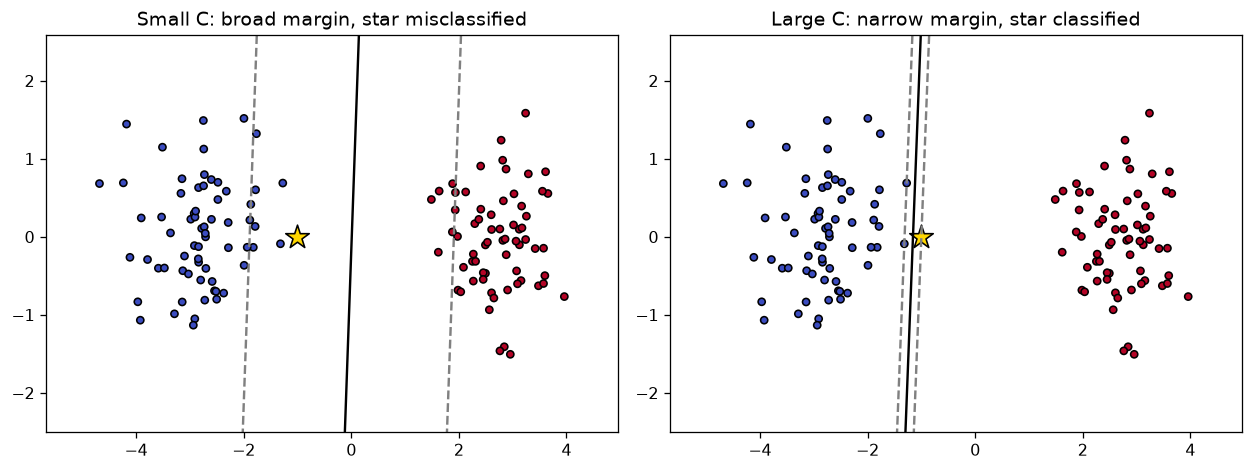

Margin width, small C: 3.79
Margin width, large C: 0.31
Star prediction, small / large C: 0 / 1 (true label = 1)


In [26]:

X_out = np.vstack([X_clear, [-1.0, 0.0]])
y_out = np.r_[y_clear, 1]
svm_lo = SVC(kernel='linear', C=0.03).fit(X_out, y_out)
svm_hi = SVC(kernel='linear', C=1000).fit(X_out, y_out)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
DecisionBoundaryDisplay.from_estimator(
    svm_lo, X_out, ax=axes[0], response_method='decision_function',
    plot_method='contour', levels=[-1, 0, 1],
    colors=['gray', 'black', 'gray'], linestyles=['--', '-', '--'])
axes[0].scatter(X_out[:, 0], X_out[:, 1], c=y_out, cmap='coolwarm', s=20, edgecolors='black')
axes[0].scatter([-1], [0], s=240, c='gold', marker='*', edgecolors='black')
axes[0].set_title('Small C: broad margin, star misclassified')

DecisionBoundaryDisplay.from_estimator(
    svm_hi, X_out, ax=axes[1], response_method='decision_function',
    plot_method='contour', levels=[-1, 0, 1],
    colors=['gray', 'black', 'gray'], linestyles=['--', '-', '--'])
axes[1].scatter(X_out[:, 0], X_out[:, 1], c=y_out, cmap='coolwarm', s=20, edgecolors='black')
axes[1].scatter([-1], [0], s=240, c='gold', marker='*', edgecolors='black')
axes[1].set_title('Large C: narrow margin, star classified')
plt.tight_layout()
plt.show()

print('Margin width, small C:', round(2 / np.linalg.norm(svm_lo.coef_[0]), 2))
print('Margin width, large C:', round(2 / np.linalg.norm(svm_hi.coef_[0]), 2))
print('Star prediction, small / large C:', svm_lo.predict([[-1.0, 0.0]])[0],
      '/', svm_hi.predict([[-1.0, 0.0]])[0], '(true label = 1)')
assert svm_lo.predict([[-1.0, 0.0]])[0] == 0
assert svm_hi.predict([[-1.0, 0.0]])[0] == 1

In [27]:
## Let's create our own SVM algo using numpy

In [40]:
X_train_small = X_clear.copy()
y_pm = np.where(y_clear == 1,1,-1)
w = np.zeros(2)
b = 0.0
learning_rate = 0.01
loss_weight = 5.0
history = []

for epoch in range(300):
    scores = X_train_small @ w + b
    margins = y_pm * scores
    active = margins < 1
    gradient_w = w - loss_weight * (np.mean((y_pm[:,None] * X_train_small) * active[:, None], axis = 0))
    gradient_b = -loss_weight * np.mean(y_pm * active)
    w = w - learning_rate * gradient_w
    b = b - learning_rate * gradient_b
    loss = 0.5 * np.dot(w, w) + loss_weight * np.mean(np.maximum(0, 1 - (y_pm * (X_train_small@w + b))))
    history.append(loss)

print("Learned w: ", np.round(w, 3), 'and b: ', round(b, 3))
print("Training accuracy: ", round(np.mean((X_train_small @ w + b > 0) == y_clear), 3))


Learned w:  [ 0.545 -0.014] and b:  -0.022
Training accuracy:  1.0


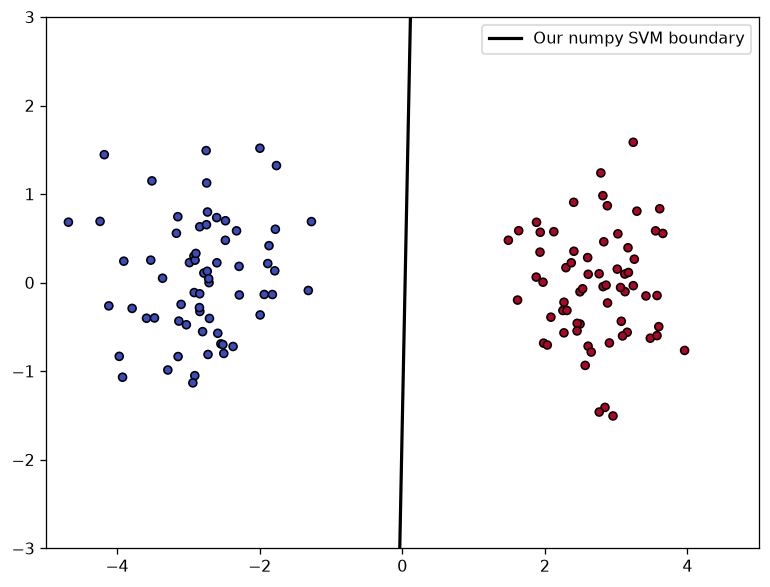

In [41]:
grid_y = np.linspace(-3, 3, 100)
plt.figure(figsize = (8, 6))
plt.scatter(X_clear[:, 0], X_clear[:, 1], c = y_clear, cmap='coolwarm', s = 25, edgecolors='black')
plt.plot((-b-w[1]*grid_y)/w[0], grid_y, c= 'black', lw =2, label = 'Our numpy SVM boundary')
plt.xlim(-5, 5)
plt.ylim(-3,3)
plt.legend()
plt.show()


Unscaled accuracy: 0.9064
Scaled accuracy: 0.9766


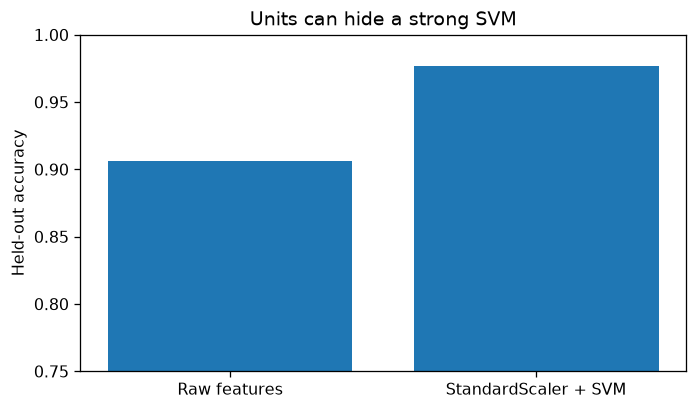

In [42]:
cancer=load_breast_cancer()
Xc_train,Xc_test,yc_train,yc_test=train_test_split(cancer.data,cancer.target,test_size=0.30,
                                                   stratify=cancer.target,random_state=42)
svm_raw=SVC(kernel='rbf',C=1,gamma='scale').fit(Xc_train,yc_train)
svm_scaled=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=1,gamma='scale')).fit(Xc_train,yc_train)
acc_raw=accuracy_score(yc_test,svm_raw.predict(Xc_test))
acc_scaled=accuracy_score(yc_test,svm_scaled.predict(Xc_test))
print('Unscaled accuracy:',round(acc_raw,4))
print('Scaled accuracy:',round(acc_scaled,4))
plt.figure(figsize=(6.8,3.8))
plt.bar(['Raw features','StandardScaler + SVM'],[acc_raw,acc_scaled])
plt.ylim(0.75,1.0);plt.ylabel('Held-out accuracy');plt.title('Units can hide a strong SVM')
plt.show()

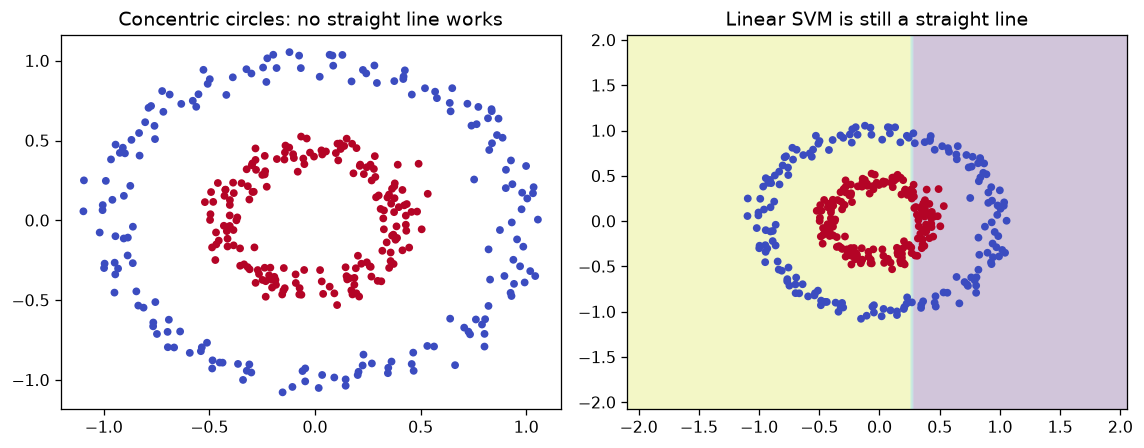

In [44]:
X_ring,y_ring=make_circles(n_samples=350,noise=0.06,factor=0.42,random_state=42)
linear_ring=SVC(kernel='linear',C=2).fit(X_ring,y_ring)
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].scatter(X_ring[:,0],X_ring[:,1],c=y_ring,cmap='coolwarm',s=15)
axes[0].set_title('Concentric circles: no straight line works')
DecisionBoundaryDisplay.from_estimator(linear_ring,X_ring,ax=axes[1],alpha=.25,response_method='predict')
axes[1].scatter(X_ring[:,0],X_ring[:,1],c=y_ring,cmap='coolwarm',s=15)
axes[1].set_title('Linear SVM is still a straight line')
plt.tight_layout();plt.show()

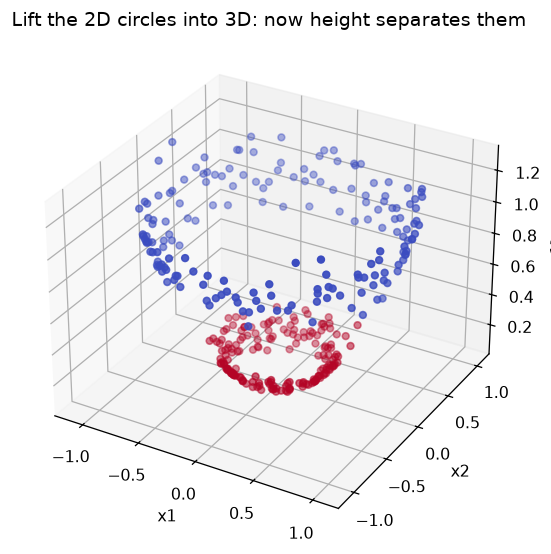

In [45]:
r_squared=X_ring[:,0]**2+X_ring[:,1]**2
fig=plt.figure(figsize=(8.5,5.7))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(X_ring[:,0],X_ring[:,1],r_squared,c=y_ring,cmap='coolwarm',s=18)
ax.set_xlabel('x1');ax.set_ylabel('x2');ax.set_zlabel('z = x1² + x2²')
ax.set_title('Lift the 2D circles into 3D: now height separates them')
plt.show()

In [47]:
x=np.array([2.,3.]); z=np.array([4.,1.])
phi_x=np.array([x[0]**2,np.sqrt(2)*x[0]*x[1],x[1]**2])
phi_z=np.array([z[0]**2,np.sqrt(2)*z[0]*z[1],z[1]**2])
print('Direct squared dot product:',(x@z)**2)
print('Expanded feature dot product:',phi_x@phi_z)
assert np.isclose((x@z)**2,phi_x@phi_z)

Direct squared dot product: 121.0
Expanded feature dot product: 121.0


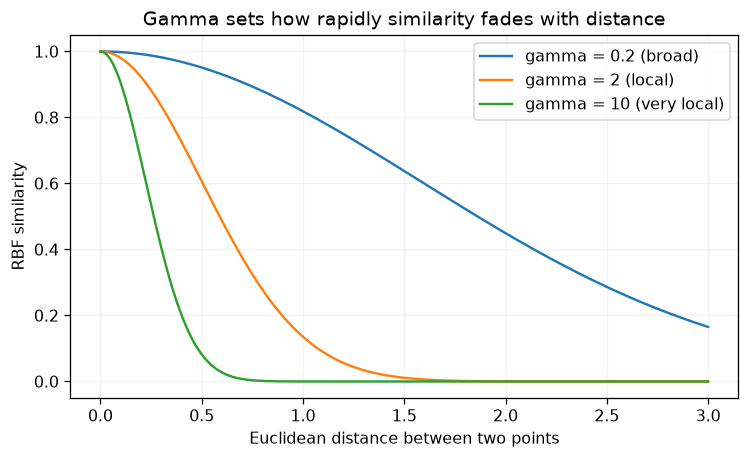

In [48]:
distance=np.linspace(0,3,200)
plt.figure(figsize=(7.5,4.1))
plt.plot(distance,np.exp(-0.2*distance**2),label='gamma = 0.2 (broad)')
plt.plot(distance,np.exp(-2*distance**2),label='gamma = 2 (local)')
plt.plot(distance,np.exp(-10*distance**2),label='gamma = 10 (very local)')
plt.xlabel('Euclidean distance between two points');plt.ylabel('RBF similarity')
plt.title('Gamma sets how rapidly similarity fades with distance')
plt.grid(alpha=.15);plt.legend();plt.show()

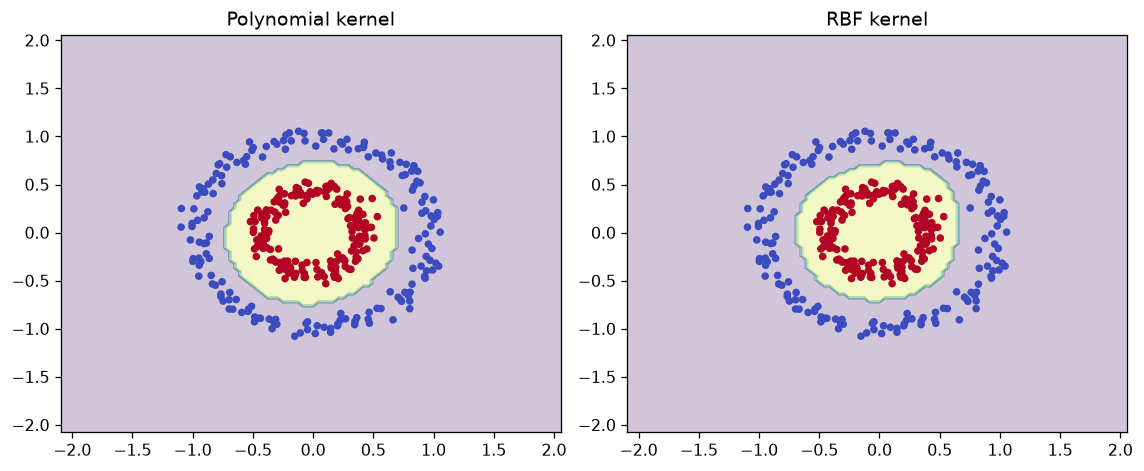

In [49]:
rbf_ring=SVC(kernel='rbf',C=10,gamma=2).fit(X_ring,y_ring)
poly_ring=SVC(kernel='poly',degree=2,C=10,gamma=1,coef0=1).fit(X_ring,y_ring)
fig,axes=plt.subplots(1,2,figsize=(10,4.2))
DecisionBoundaryDisplay.from_estimator(poly_ring,X_ring,ax=axes[0],response_method='predict',alpha=.25)
axes[0].scatter(X_ring[:,0],X_ring[:,1],c=y_ring,cmap='coolwarm',s=14)
axes[0].set_title('Polynomial kernel')
DecisionBoundaryDisplay.from_estimator(rbf_ring,X_ring,ax=axes[1],response_method='predict',alpha=.25)
axes[1].scatter(X_ring[:,0],X_ring[:,1],c=y_ring,cmap='coolwarm',s=14)
axes[1].set_title('RBF kernel')
plt.tight_layout();plt.show()

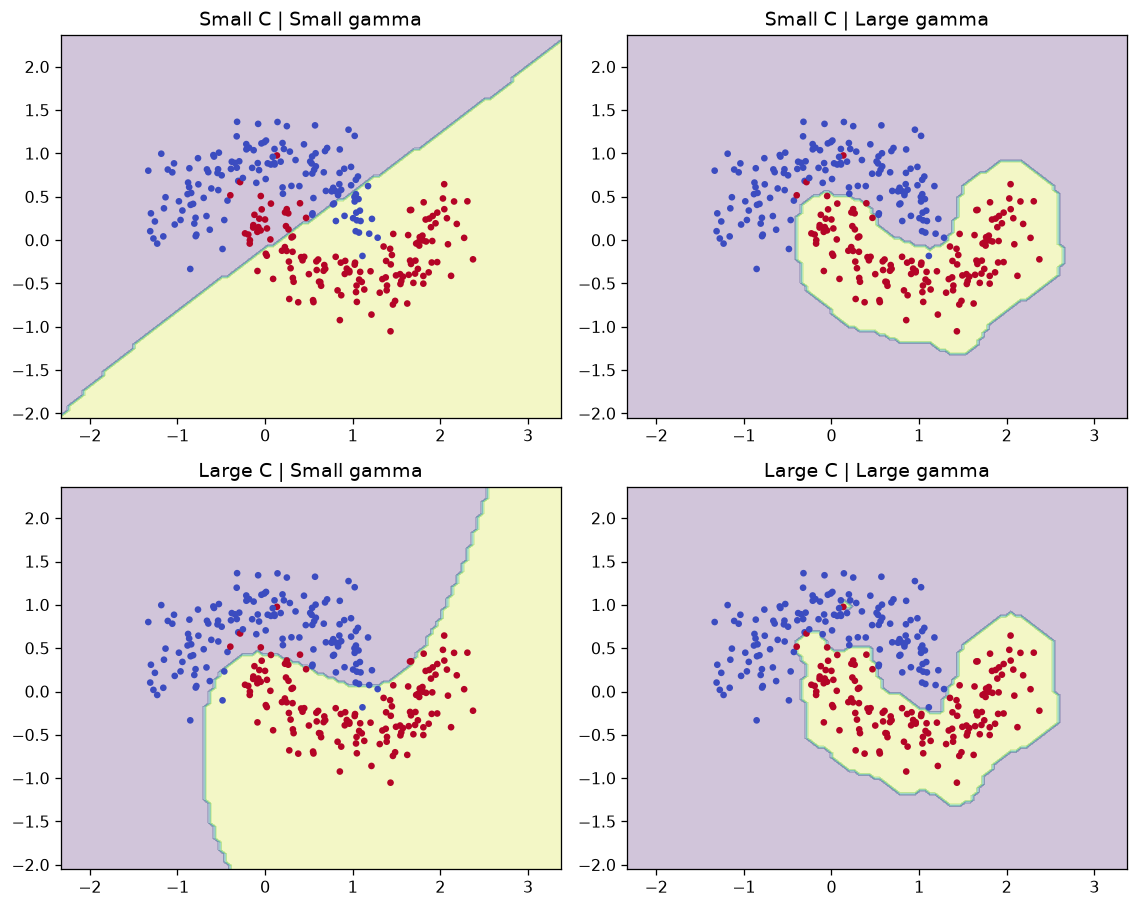

In [50]:
c1g1=SVC(C=0.1,gamma=0.1).fit(X_moon,y_moon)
c1g2=SVC(C=0.1,gamma=20).fit(X_moon,y_moon)
c2g1=SVC(C=100,gamma=0.1).fit(X_moon,y_moon)
c2g2=SVC(C=100,gamma=20).fit(X_moon,y_moon)
fig,axes=plt.subplots(2,2,figsize=(10,8))
DecisionBoundaryDisplay.from_estimator(c1g1,X_moon,ax=axes[0,0],response_method='predict',alpha=.25)
axes[0,0].scatter(X_moon[:,0],X_moon[:,1],c=y_moon,cmap='coolwarm',s=10)
axes[0,0].set_title('Small C | Small gamma')
DecisionBoundaryDisplay.from_estimator(c1g2,X_moon,ax=axes[0,1],response_method='predict',alpha=.25)
axes[0,1].scatter(X_moon[:,0],X_moon[:,1],c=y_moon,cmap='coolwarm',s=10)
axes[0,1].set_title('Small C | Large gamma')
DecisionBoundaryDisplay.from_estimator(c2g1,X_moon,ax=axes[1,0],response_method='predict',alpha=.25)
axes[1,0].scatter(X_moon[:,0],X_moon[:,1],c=y_moon,cmap='coolwarm',s=10)
axes[1,0].set_title('Large C | Small gamma')
DecisionBoundaryDisplay.from_estimator(c2g2,X_moon,ax=axes[1,1],response_method='predict',alpha=.25)
axes[1,1].scatter(X_moon[:,0],X_moon[:,1],c=y_moon,cmap='coolwarm',s=10)
axes[1,1].set_title('Large C | Large gamma')
plt.tight_layout();plt.show()

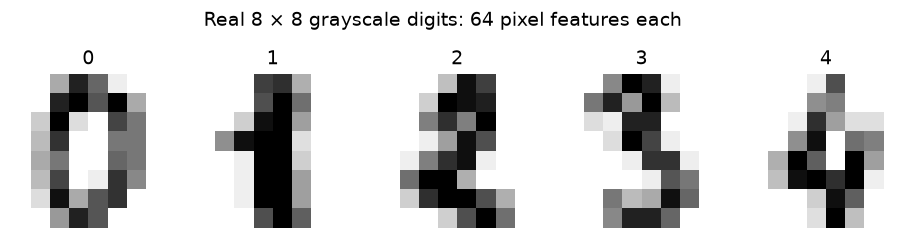

In [51]:
digits=load_digits()
fig,axes=plt.subplots(1,5,figsize=(10,2.5))
axes[0].imshow(digits.images[0],cmap='gray_r');axes[0].set_title(str(digits.target[0]));axes[0].axis('off')
axes[1].imshow(digits.images[1],cmap='gray_r');axes[1].set_title(str(digits.target[1]));axes[1].axis('off')
axes[2].imshow(digits.images[2],cmap='gray_r');axes[2].set_title(str(digits.target[2]));axes[2].axis('off')
axes[3].imshow(digits.images[3],cmap='gray_r');axes[3].set_title(str(digits.target[3]));axes[3].axis('off')
axes[4].imshow(digits.images[4],cmap='gray_r');axes[4].set_title(str(digits.target[4]));axes[4].axis('off')
plt.suptitle('Real 8 × 8 grayscale digits: 64 pixel features each');plt.show()

In [52]:
Xd_train,Xd_test,yd_train,yd_test=train_test_split(digits.data,digits.target,test_size=0.25,
                                                    stratify=digits.target,random_state=42)
print('Training rows:',len(Xd_train),'Sealed test rows:',len(Xd_test))
parameters={'C':[1,10,100],'gamma':['scale',0.001,0.005]}
search=GridSearchCV(SVC(kernel='rbf'), parameters,
                    cv=3, scoring='accuracy', n_jobs=1)
start=time.perf_counter()
search.fit(Xd_train,yd_train)
search_time=time.perf_counter()-start
print('Best CV parameters:',search.best_params_)
print('Best CV accuracy:',round(search.best_score_,4))
print('Search seconds (local only):',round(search_time,2))

Training rows: 1347 Sealed test rows: 450
Best CV parameters: {'C': 10, 'gamma': 0.001}
Best CV accuracy: 0.9926
Search seconds (local only): 1.33


In [53]:
digit_predictions=search.best_estimator_.predict(Xd_test)
digit_accuracy=accuracy_score(yd_test,digit_predictions)
wrong=np.flatnonzero(digit_predictions!=yd_test)
print('Sealed test accuracy:',round(digit_accuracy,4))
print('Misclassified images:',len(wrong),'out of',len(yd_test))
assert 0.90<digit_accuracy<=1.0

Sealed test accuracy: 0.9889
Misclassified images: 5 out of 450


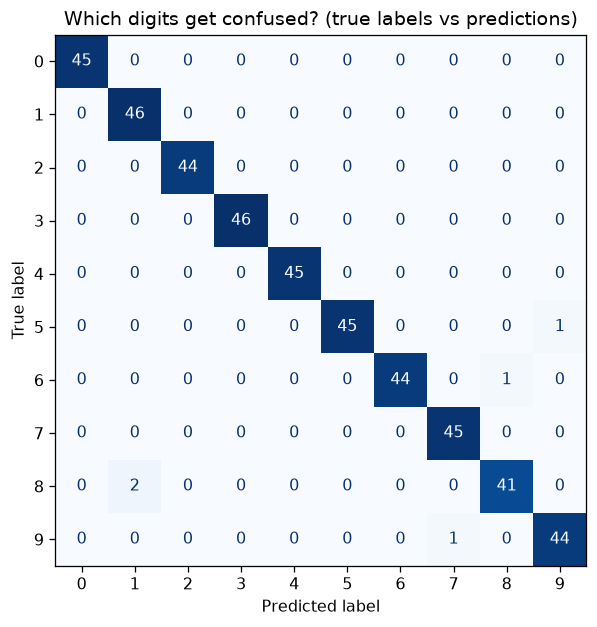

In [54]:
fig,ax=plt.subplots(figsize=(7.5,6))
ConfusionMatrixDisplay.from_predictions(yd_test,digit_predictions,ax=ax,cmap='Blues',colorbar=False)
ax.set_title('Which digits get confused? (true labels vs predictions)')
plt.show()

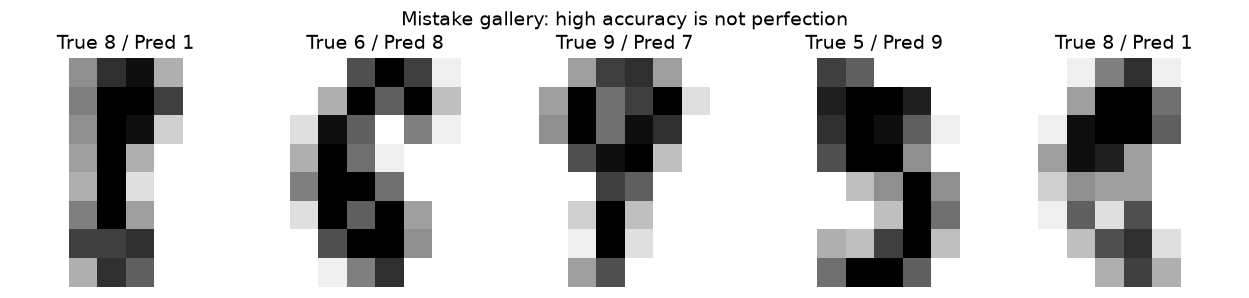

In [55]:
fig,axes=plt.subplots(1,5,figsize=(11,2.6))
show_ids=wrong[:5]
if len(show_ids)>0:
    axes[0].imshow(Xd_test[show_ids[0]].reshape(8,8),cmap='gray_r')
    axes[0].set_title(f'True {yd_test[show_ids[0]]} / Pred {digit_predictions[show_ids[0]]}')
if len(show_ids)>1:
    axes[1].imshow(Xd_test[show_ids[1]].reshape(8,8),cmap='gray_r')
    axes[1].set_title(f'True {yd_test[show_ids[1]]} / Pred {digit_predictions[show_ids[1]]}')
if len(show_ids)>2:
    axes[2].imshow(Xd_test[show_ids[2]].reshape(8,8),cmap='gray_r')
    axes[2].set_title(f'True {yd_test[show_ids[2]]} / Pred {digit_predictions[show_ids[2]]}')
if len(show_ids)>3:
    axes[3].imshow(Xd_test[show_ids[3]].reshape(8,8),cmap='gray_r')
    axes[3].set_title(f'True {yd_test[show_ids[3]]} / Pred {digit_predictions[show_ids[3]]}')
if len(show_ids)>4:
    axes[4].imshow(Xd_test[show_ids[4]].reshape(8,8),cmap='gray_r')
    axes[4].set_title(f'True {yd_test[show_ids[4]]} / Pred {digit_predictions[show_ids[4]]}')
axes[0].axis('off');axes[1].axis('off');axes[2].axis('off');axes[3].axis('off');axes[4].axis('off')
plt.suptitle('Mistake gallery: high accuracy is not perfection');plt.tight_layout();plt.show()

In [56]:
cancer_scores=svm_scaled.decision_function(Xc_test)
auc=roc_auc_score(yc_test,cancer_scores)
print('Breast-cancer ROC-AUC from decision_function:',round(auc,4))
assert 0.85<auc<=1.0

Breast-cancer ROC-AUC from decision_function: 0.9978


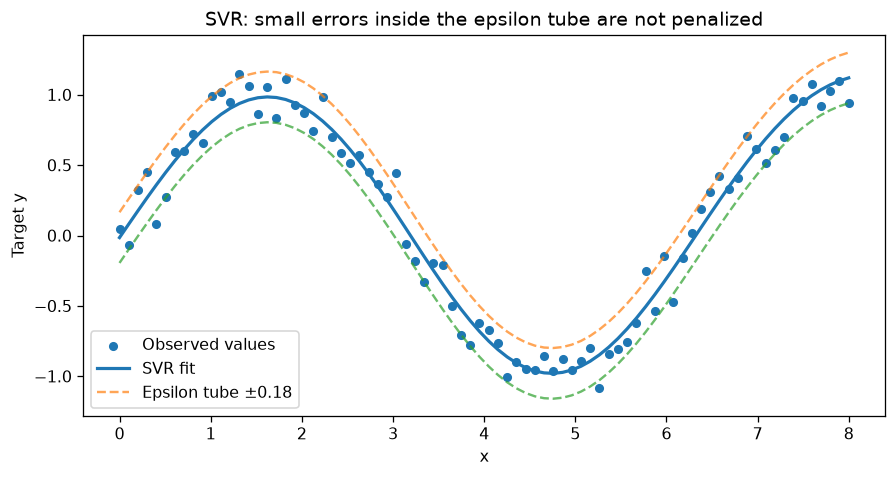

In [57]:
rng=np.random.default_rng(42)
X_reg=np.linspace(0,8,80).reshape(-1,1)
y_reg=np.sin(X_reg[:,0])+rng.normal(0,0.16,len(X_reg))
svr=make_pipeline(StandardScaler(),SVR(kernel='rbf',C=8,gamma=0.5,epsilon=0.18))
svr.fit(X_reg,y_reg)
reg_pred=svr.predict(X_reg)
plt.figure(figsize=(9,4.3))
plt.scatter(X_reg[:,0],y_reg,s=22,label='Observed values')
plt.plot(X_reg[:,0],reg_pred,lw=2,label='SVR fit')
plt.plot(X_reg[:,0],reg_pred+0.18,'--',alpha=.7,label='Epsilon tube ±0.18')
plt.plot(X_reg[:,0],reg_pred-0.18,'--',alpha=.7)
plt.xlabel('x');plt.ylabel('Target y')
plt.title('SVR: small errors inside the epsilon tube are not penalized')
plt.legend();plt.show()

SVC seconds (2k, 5k, 10k): 0.045 0.182 0.48
HistGB seconds (2k, 5k, 10k): 0.15 0.156 0.163


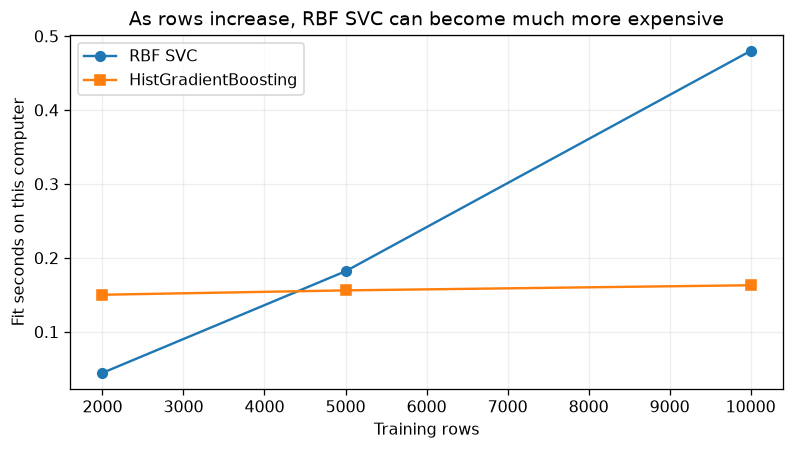

In [58]:
rng = np.random.default_rng(5)
X_speed = rng.normal(size=(10000, 12))
y_speed = (X_speed[:, 0] + 0.5 * X_speed[:, 1] > 0).astype(int)

# Repeat the exact same simple timing pattern at three row counts.
start = time.perf_counter()
SVC(kernel='rbf').fit(X_speed[:2000], y_speed[:2000])
svm_2k = time.perf_counter() - start
start = time.perf_counter()
SVC(kernel='rbf').fit(X_speed[:5000], y_speed[:5000])
svm_5k = time.perf_counter() - start
start = time.perf_counter()
SVC(kernel='rbf').fit(X_speed, y_speed)
svm_10k = time.perf_counter() - start

start = time.perf_counter()
HistGradientBoostingClassifier(max_iter=50, random_state=5).fit(X_speed[:2000], y_speed[:2000])
hist_2k = time.perf_counter() - start
start = time.perf_counter()
HistGradientBoostingClassifier(max_iter=50, random_state=5).fit(X_speed[:5000], y_speed[:5000])
hist_5k = time.perf_counter() - start
start = time.perf_counter()
HistGradientBoostingClassifier(max_iter=50, random_state=5).fit(X_speed, y_speed)
hist_10k = time.perf_counter() - start

print('SVC seconds (2k, 5k, 10k):', round(svm_2k, 3), round(svm_5k, 3), round(svm_10k, 3))
print('HistGB seconds (2k, 5k, 10k):', round(hist_2k, 3), round(hist_5k, 3), round(hist_10k, 3))
plt.figure(figsize=(8, 4))
plt.plot([2000, 5000, 10000], [svm_2k, svm_5k, svm_10k], 'o-', label='RBF SVC')
plt.plot([2000, 5000, 10000], [hist_2k, hist_5k, hist_10k], 's-', label='HistGradientBoosting')
plt.xlabel('Training rows')
plt.ylabel('Fit seconds on this computer')
plt.title('As rows increase, RBF SVC can become much more expensive')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [59]:
print('FINAL SESSION SCOREBOARD')
print('Support vectors in 500-point demo:',len(kept))
print('Breast-cancer accuracy raw / scaled:',round(acc_raw,3),'/',round(acc_scaled,3))
print('Handwritten digits best CV parameters:',search.best_params_)
print('Handwritten digits sealed test accuracy:',round(digit_accuracy,3))
print('Breast-cancer ROC AUC:',round(auc,3))

FINAL SESSION SCOREBOARD
Support vectors in 500-point demo: 12
Breast-cancer accuracy raw / scaled: 0.906 / 0.977
Handwritten digits best CV parameters: {'C': 10, 'gamma': 0.001}
Handwritten digits sealed test accuracy: 0.989
Breast-cancer ROC AUC: 0.998
